Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project Root Path set to: /content/drive/MyDrive/AIvy - AI Powered Job Recommendation System
Results Path set to: /content/drive/MyDrive/AIvy - AI Powered Job Recommendation System/Results

✓ Successfully found results directory.
Contents: ['Model 02 - outputs', 'Model 03 - outputs', 'Model 04 - outputs', 'Model 05 - outputs', 'Model 06 - outputs', 'Model 01 - outputs', 'cb 2 outputs', 'XG 2 outputs', 'Model 04 - outputs-categorical_features.png', 'Model 04 - outputs-numerical_features_summary.csv', 'Model 04 - outputs-02_numerical_stats.png', 'Model 04 - outputs-03_target_by_categories.png', 'Model 04 - outputs-Results', 'Model_04', 'Model 04 - outputs-Hyperparameter_Tuning_Optimized_2025-10-23_06-15-07.json', 'Model 04 - outputs-visualizations', 'Model 04 - outputs-04_cv_scores.png', 'Model 04 - outputs-05_confusion_matrix.png', 'Model 04 - outputs-06_featu

,Model,Accuracy,Precision,Recall,F1-Score
1,XGBoost,68.42,0.61,0.68,0.63



 BEST PERFORMING MODEL: XGBoost
   Accuracy: 68.42%
   F1-Score: 0.6300

VISUALIZATIONS


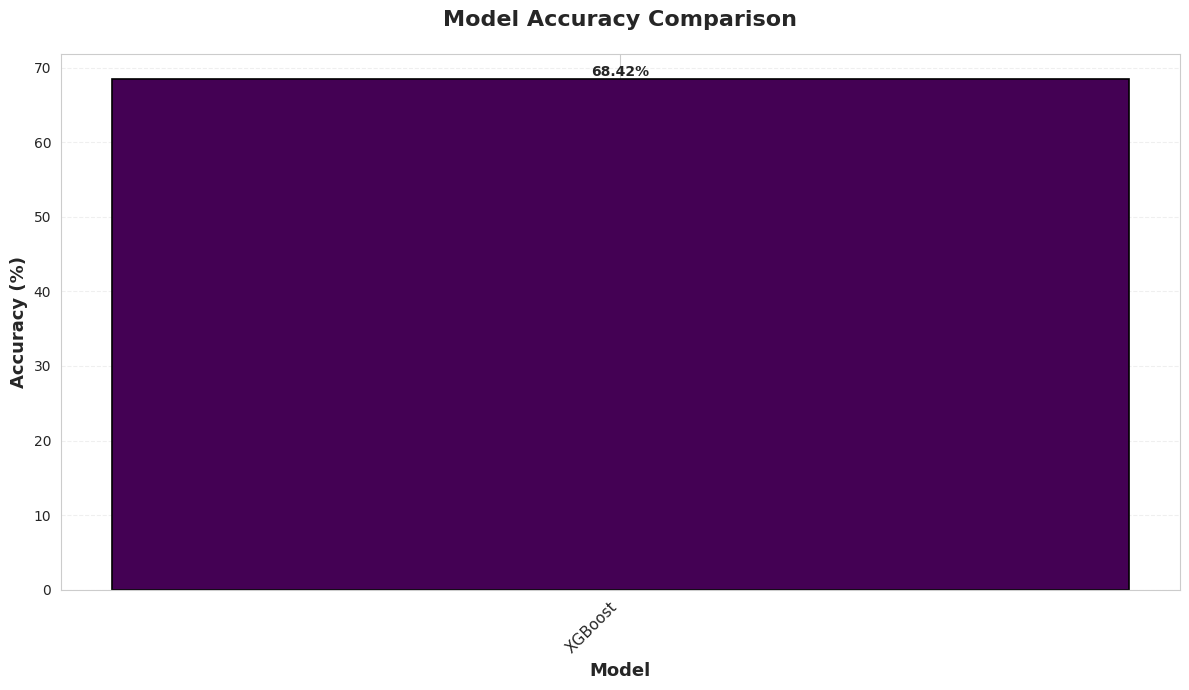

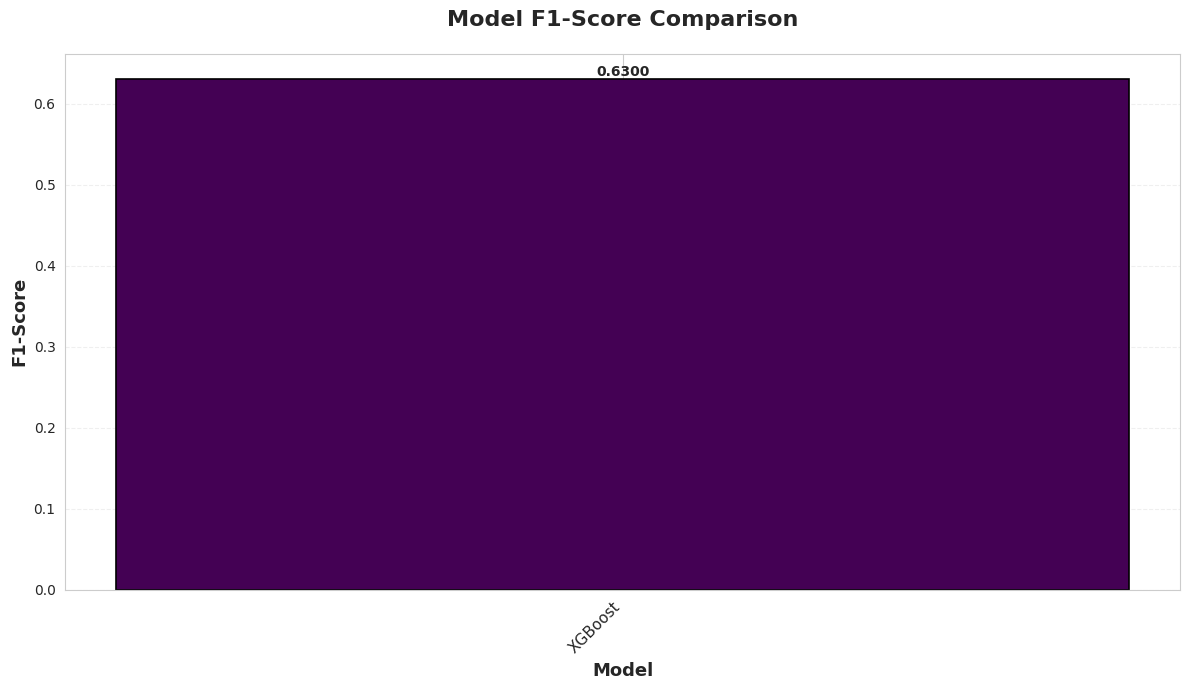


 Generating combined metrics comparison...


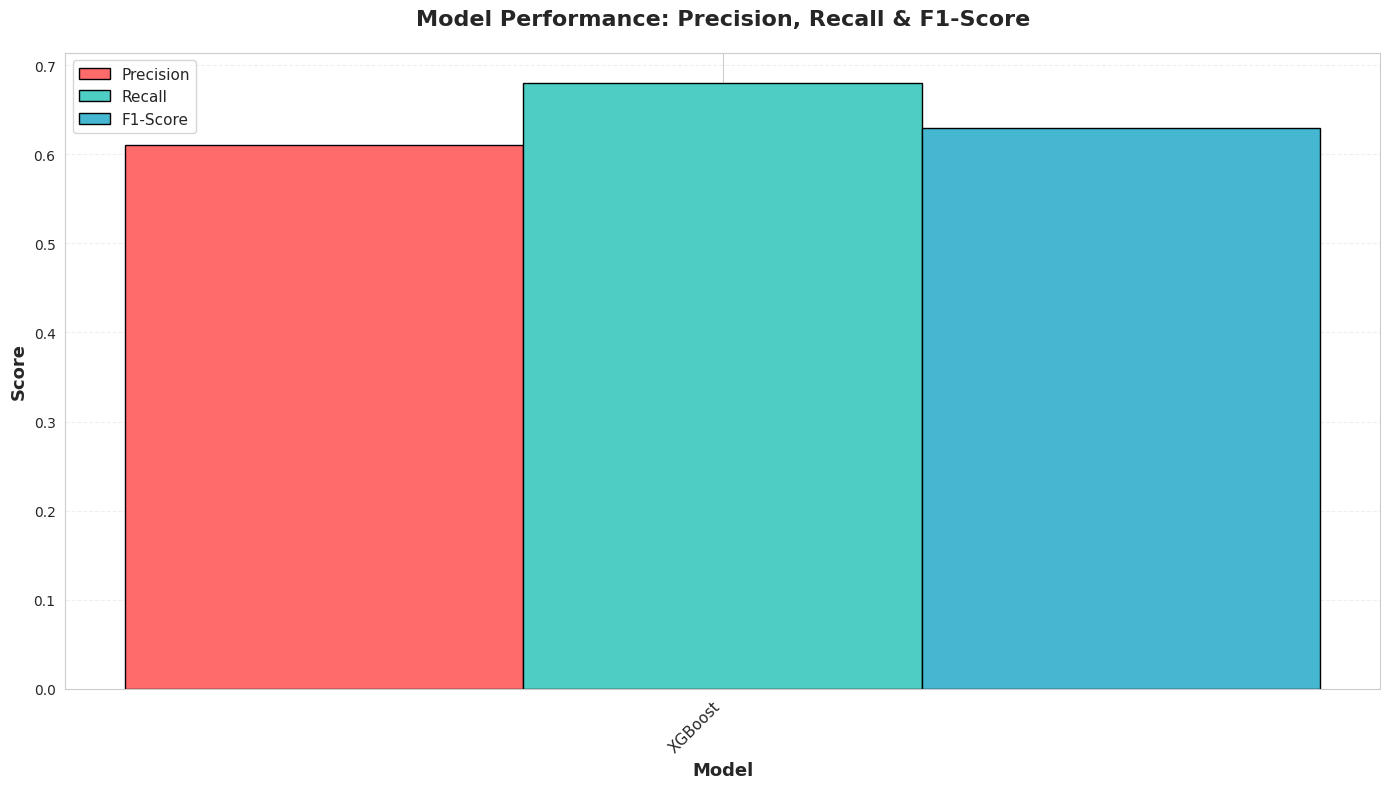


SUMMARY STATISTICS



,Accuracy,Precision,Recall,F1-Score
count,1.00,1.00,1.00,1.00
mean,68.42,0.61,0.68,0.63
std,NaN,NaN,NaN,NaN
min,68.42,0.61,0.68,0.63
25%,68.42,0.61,0.68,0.63
50%,68.42,0.61,0.68,0.63
75%,68.42,0.61,0.68,0.63
max,68.42,0.61,0.68,0.63



✓ Analysis Complete!

 Results exported to: /content/drive/MyDrive/AIvy - AI Powered Job Recommendation System/Results/model_comparison_summary.csv


In [15]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from IPython.display import display
import numpy as np

# Set style for better-looking plots
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# --- NEW Custom Parsing Function for XGBoost Results ---
def read_xgboost_results(filepath):
    """
    Parses the specific metrics (Test Set Accuracy, Precision, Recall, F1-Score)
    from the xgboost_tuning_results.txt file created in the previous step.
    """
    accuracy = None
    precision = None
    recall = None
    f1_score = None

    try:
        with open(filepath, 'r') as f:
            content = f.read()
    except FileNotFoundError:
        raise FileNotFoundError(f"XGBoost results file not found at: {filepath}")

    # 1. Extract Accuracy (look for the Test Set Accuracy)
    # Example match: Test Set Accuracy: 0.5790
    acc_match = re.search(r'Test Set Accuracy:\s*(\d+\.\d+)', content)
    if acc_match:
        accuracy = float(acc_match.group(1)) * 100 # Convert 0.xxxx to percentage

    # 2. Extract Classification Report for 'weighted avg'
    # We look for a line containing "weighted avg" followed by three decimal numbers
    # which correspond to Precision, Recall, and F1-Score.
    weighted_avg_match = re.search(
        r'weighted avg\s+(\d+\.\d+)\s+(\d+\.\d+)\s+(\d+\.\d+)',
        content
    )

    if weighted_avg_match:
        precision = float(weighted_avg_match.group(1))
        recall = float(weighted_avg_match.group(2))
        f1_score = float(weighted_avg_match.group(3))

    if accuracy is None or precision is None:
        raise ValueError("Could not parse Test Set Accuracy or weighted avg metrics.")

    return accuracy, precision, recall, f1_score


# --- Cell 2: Setup Paths (UPDATED for AIvy Project) ---
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

project_root_path = ''

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # CRITICAL FIX: Updated path to your AIvy project root
    project_root_path = '/content/drive/MyDrive/AIvy - AI Powered Job Recommendation System'
else:
    # Path for local execution
    project_root_path = '../..'

# Define the results path based on the root (where XGBoost results were saved)
results_path = os.path.join(project_root_path, 'Results')

# Verify the path exists
print(f"Project Root Path set to: {project_root_path}")
print(f"Results Path set to: {results_path}")

if not os.path.isdir(results_path):
    print(f"\n ERROR: The results directory was not found at '{results_path}'")
    print("Please ensure the 'project_root_path' is correct and the folder exists.")
else:
    print("\n✓ Successfully found results directory.")
    print(f"Contents: {os.listdir(results_path)}")


# --- Cell 3: Model Definitions (UPDATED for XGBoost) ---
# NOTE: We assume the other models you ran previously saved their metrics
# into the NEW 'Results' directory under subfolders named similar to the old project.
models = {
    'Logistic Regression': 'logistic_regression_results',
    'Naive Bayes': 'naive_bayes_results',
    'Random Forest': 'random_forest_results', # Generic name for consistency
    'SVM': 'svm_results',                   # Generic name for consistency
    'LightGBM': 'lightgbm_results',
    'Neural Network': 'neural_network_results',
    'XGBoost': 'xgboost_results'  # Placeholder for the new model
}

print("\n--- Model folders to search for: ---")
for name, folder in models.items():
    if name == 'XGBoost':
        print(f"  • {name}: {os.path.join(results_path, 'xgboost_tuning_results.txt')}")
    else:
        print(f"  • {name}: {os.path.join(results_path, folder)} (Requires accuracy.txt and classification_report.csv)")


# --- Cell 4: Utility Function (Unchanged, primarily for older files) ---
def extract_accuracy(text):
    # Logic to extract accuracy, typically from the 'accuracy.txt' file
    decimal_match = re.search(r'(?:Final|Tuned|Model)?\s*(?:Model)?\s*Accuracy[:\s]*(\d+\.\d+)', text, re.IGNORECASE)
    if decimal_match:
        value = float(decimal_match.group(1))
        if value <= 1.0:
            return value * 100
        return value

    percent_match = re.search(r'(\d+\.\d+)%', text)
    if percent_match:
        return float(percent_match.group(1))

    number_match = re.search(r'(\d+\.\d+)', text)
    if number_match:
        value = float(number_match.group(1))
        if value <= 1.0:
            return value * 100
        return value

    raise ValueError(f"Could not extract accuracy from: {text}")


# --- Cell 5: Loading Model Results (UPDATED Logic) ---
performance_data = []
print("\nLOADING MODEL RESULTS")

for model_name, folder in models.items():

    if model_name == 'XGBoost':
        # --- Handle XGBoost single text file ---
        result_file = os.path.join(results_path, 'xgboost_tuning_results.txt')
        print(f"\n Checking: {model_name}")

        try:
            accuracy, precision, recall, f1_score = read_xgboost_results(result_file)

            performance_data.append({
                'Model': model_name,
                'Accuracy': accuracy,
                'Precision': precision,
                'Recall': recall,
                'F1-Score': f1_score
            })
            print(f"     SUCCESS: All metrics loaded from {os.path.basename(result_file)}")
            print(f"      Accuracy: {accuracy:.2f}%, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1_score:.4f}")

        except FileNotFoundError as e:
            print(f"    SKIPPED: File not found - {e}")
        except ValueError as e:
            print(f"    SKIPPED: Parsing failed - {e}")
        except Exception as e:
            print(f"    SKIPPED: Unexpected error during XGBoost parse - {type(e)._name_}: {e}")

    else:
        # --- Handle other models (Expected Folder Structure) ---
        model_result_path = os.path.join(results_path, folder)
        print(f"\n Checking: {model_name} (Path: {model_result_path})")

        if not os.path.isdir(model_result_path):
            print(f"    SKIPPED: Directory not found")
            continue

        try:
            accuracy_path = os.path.join(model_result_path, 'accuracy.txt')
            report_path = os.path.join(model_result_path, 'classification_report.csv')

            # Check if files exist
            if not os.path.exists(accuracy_path) or not os.path.exists(report_path):
                print(f"    SKIPPED: Required metric files (accuracy.txt/classification_report.csv) not found")
                continue

            # Read accuracy file
            with open(accuracy_path, 'r') as f:
                accuracy_text = f.read().strip()
                print(f"    Raw accuracy text: {accuracy_text[:100]}...")

            # Extract accuracy
            accuracy = extract_accuracy(accuracy_text)
            print(f"    Extracted accuracy: {accuracy:.2f}%")

            # Read classification report
            report_df = pd.read_csv(report_path)

            # Find the class column
            class_col = 'Unnamed: 0' if 'Unnamed: 0' in report_df.columns else report_df.columns[0]

            # Extract weighted average metrics
            weighted_avg = report_df[report_df[class_col].astype(str).str.contains('weighted avg', case=False, na=False)]

            if weighted_avg.empty:
                print(f"    SKIPPED: Could not find weighted average in classification report")
                continue

            precision = weighted_avg['precision'].iloc[0]
            recall = weighted_avg['recall'].iloc[0]
            f1_score = weighted_avg['f1-score'].iloc[0]

            if np.isnan(precision) or np.isnan(recall) or np.isnan(f1_score):
                 print(f"    SKIPPED: Extracted metrics contain NaN values.")
                 continue

            performance_data.append({
                'Model': model_name,
                'Accuracy': accuracy,
                'Precision': precision,
                'Recall': recall,
                'F1-Score': f1_score
            })
            print(f"     SUCCESS: All metrics loaded")
            print(f"      Accuracy: {accuracy:.2f}%, Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1_score:.4f}")

        except Exception as e:
            print(f"    SKIPPED: Unexpected error loading metrics - {type(e)._name_}: {e}")

# --- Cell 6: Display Results ---
print(f"\nLOADING COMPLETE: {len(performance_data)} models loaded successfully")

results_df = pd.DataFrame(performance_data)

print("\nMODEL PERFORMANCE COMPARISON")


if not results_df.empty:
    # Sort by Accuracy (descending) and display
    sorted_results = results_df.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)
    sorted_results.index = sorted_results.index + 1  # Start index from 1

    display(sorted_results.round(4))

    # Print summary
    best_model = sorted_results.iloc[0]
    print(f"\n BEST PERFORMING MODEL: {best_model['Model']}")
    print(f"   Accuracy: {best_model['Accuracy']:.2f}%")
    print(f"   F1-Score: {best_model['F1-Score']:.4f}")

else:
    print(" No model results were loaded successfully.")

# --- Cell 7: Plot Accuracy ---
def plot_comparison(metric, title, ylabel=None, percentage=False):
    if results_df.empty:
        print(f"  Cannot generate plot for '{metric}' - no data available")
        return

    plot_data = results_df.sort_values(by=metric, ascending=False)
    plt.figure(figsize=(12, 7))
    colors = plt.cm.viridis(np.linspace(0, 1, len(plot_data)))
    bars = plt.bar(range(len(plot_data)), plot_data[metric], color=colors, edgecolor='black', linewidth=1.2)

    plt.title(title, fontsize=16, weight='bold', pad=20)
    plt.xlabel('Model', fontsize=13, weight='bold')
    plt.ylabel(ylabel if ylabel else metric, fontsize=13, weight='bold')
    plt.xticks(range(len(plot_data)), plot_data['Model'], rotation=45, ha='right', fontsize=11)

    for i, (bar, value) in enumerate(zip(bars, plot_data[metric])):
        height = bar.get_height()
        label = f'{value:.2f}%' if percentage else f'{value:.4f}'
        plt.text(bar.get_x() + bar.get_width()/2., height, label, ha='center', va='bottom', fontsize=10, weight='bold')

    plt.grid(axis='y', alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()

if not results_df.empty:
    print("\nVISUALIZATIONS")
    plot_comparison('Accuracy', 'Model Accuracy Comparison', ylabel='Accuracy (%)', percentage=True)

# --- Cell 8: Plot F1-Score ---
if not results_df.empty:
    plot_comparison('F1-Score', 'Model F1-Score Comparison', ylabel='F1-Score')

# --- Cell 9: Plot Combined Metrics ---
if not results_df.empty:
    print("\n Generating combined metrics comparison...")

    plt.figure(figsize=(14, 8))
    x = np.arange(len(results_df))
    width = 0.25
    plot_data = results_df.sort_values(by='F1-Score', ascending=False)

    plt.bar(x - width, plot_data['Precision'], width, label='Precision', color='#FF6B6B', edgecolor='black', linewidth=1)
    plt.bar(x, plot_data['Recall'], width, label='Recall', color='#4ECDC4', edgecolor='black', linewidth=1)
    plt.bar(x + width, plot_data['F1-Score'], width, label='F1-Score', color='#45B7D1', edgecolor='black', linewidth=1)

    plt.xlabel('Model', fontsize=13, weight='bold')
    plt.ylabel('Score', fontsize=13, weight='bold')
    plt.title('Model Performance: Precision, Recall & F1-Score', fontsize=16, weight='bold', pad=20)
    plt.xticks(x, plot_data['Model'], rotation=45, ha='right', fontsize=11)
    plt.legend(fontsize=11, loc='best')
    plt.grid(axis='y', alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()

# --- Cell 10: Summary Statistics ---
if not results_df.empty:
    print("\n" + "="*60)
    print("SUMMARY STATISTICS")
    print("="*60 + "\n")

    summary_stats = results_df[['Accuracy', 'Precision', 'Recall', 'F1-Score']].describe()
    display(summary_stats.round(4))

    print("\n✓ Analysis Complete!")

# --- Cell 11: Export Results ---
if not results_df.empty:
    try:
        output_path = os.path.join(results_path, 'model_comparison_summary.csv')
        results_df.to_csv(output_path, index=False)
        print(f"\n Results exported to: {output_path}")
    except Exception as e:
        print(f"\n  Could not export results: {e}")

In [6]:
# ============================================================================
# GROUP PIPELINE - STEP 2: LOAD ALL TRAINED MODELS
# ============================================================================

print("\n" + "="*70)
print("LOADING ALL TRAINED MODELS")
print("="*70)

!pip install catboost
from catboost import CatBoostClassifier
from sklearn.preprocessing import StandardScaler

# Define model information
models_info = {
    'XGBoost': {
        'path': f'{base_path}/XGBoost/models/xgboost_model.pkl',
        'color': 'steelblue',
        'marker': 'o',
        'needs_scaling': False
    },
    'LightGBM': {
        'path': f'{base_path}/LightGBM/models/lightgbm_model.pkl',
        'color': 'forestgreen',
        'marker': 's',
        'needs_scaling': False
    },
    'Random Forest': {
        'path': f'{base_path}/RandomForest/models/randomforest_model.pkl',
        'color': 'mediumpurple',
        'marker': 'D',
        'needs_scaling': False
    },
    'CatBoost': {
        'path': f'{base_path}/CatBoost/models/catboost_model.cbm',
        'color': 'darkorange',
        'marker': '*',
        'needs_scaling': False
    },
    'MLP': {
        'path': f'{base_path}/MLP/models/mlp_model.pkl',
        'scaler_path': f'{base_path}/MLP/models/scaler.pkl',
        'color': 'crimson',
        'marker': 'H',
        'needs_scaling': True
    },
    'Logistic Regression': {
        'path': f'{base_path}/LogisticRegression/models/logistic_regression_model.pkl',
        'scaler_path': f'{base_path}/LogisticRegression/models/scaler.pkl',
        'color': 'gold',
        'marker': 'p',
        'needs_scaling': True
    }
}

# Load models
loaded_models = {}
scalers = {}
failed_models = []

print("\nLoading models...")

for model_name, info in models_info.items():
    try:
        # Check if model file exists
        if not os.path.exists(info['path']):
            print(f"{model_name}: Model file not found at {info['path']}")
            failed_models.append(model_name)
            continue

        # Load model
        if model_name == 'CatBoost':
            model = CatBoostClassifier()
            model.load_model(info['path'])
        else:
            model = joblib.load(info['path'])

        loaded_models[model_name] = model

        # Load scaler if needed
        if info.get('needs_scaling', False):
            scaler_path = info.get('scaler_path')
            if scaler_path and os.path.exists(scaler_path):
                scalers[model_name] = joblib.load(scaler_path)
                print(f"{model_name}: Loaded (with scaler)")
            else:
                print(f"{model_name}: Scaler not found at {scaler_path}")
                failed_models.append(model_name)
                del loaded_models[model_name]
        else:
            print(f"{model_name}: Loaded")

    except Exception as e:
        print(f"{model_name}: Failed to load - {str(e)}")
        failed_models.append(model_name)

print(f"\nSummary:")
print(f"   Successfully loaded: {len(loaded_models)} models")
print(f"   Failed to load: {len(failed_models)} models")

if failed_models:
    print(f"   Failed models: {', '.join(failed_models)}")

if len(loaded_models) == 0:
    print("\nERROR: No models loaded! Please train models first.")
    print("   Run the individual model training scripts before the group pipeline.")
else:
    print(f"\nReady to proceed with {len(loaded_models)} models")



LOADING ALL TRAINED MODELS
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.6 MB/s eta 0:00:00

Loading models...
XGBoost: Model file not found at /content/drive/MyDrive/AIvy - AI Powered Job Recommendation System/Pace 02 - model training/XGBoost/models/xgboost_model.pkl
LightGBM: Model file not found at /content/drive/MyDrive/AIvy - AI Powered Job Recommendation System/Pace 02 - model training/LightGBM/models/lightgbm_model.pkl
Random Forest: Model file not found at /content/drive/MyDrive/AIvy - AI Powered Job Recommendation System/Pace 02 - model training/RandomForest/models/randomforest_model.pkl
CatBoost: Model file not found at /content/drive/MyDrive/AIvy - AI Powered Job Recommendation System/Pace 02 - model training/CatBoost/models/catboost_model.cbm
MLP: Model file not found at /content/drive/MyDrive/AIvy - AI Powered Job Recommendation System/Pace 02 - model training/MLP/models/mlp_model.pkl
Logistic Regression: Model file not found at /content/drive/MyDrive/AIvy - 

In [7]:
# ============================================================================
# GROUP PIPELINE - STEP 3: GENERATE PREDICTIONS
# ============================================================================

print("\n" + "="*70)
print("GENERATING PREDICTIONS FROM ALL MODELS")
print("="*70)

all_predictions = {}
all_probabilities = {}
all_metrics = {}

for model_name, model in loaded_models.items():
    try:
        print(f"\nProcessing: {model_name}")

        # Prepare input data (scale if needed)
        if models_info[model_name].get('needs_scaling', False):
            if model_name in scalers:
                X_test_input = scalers[model_name].transform(X_test)
                print(f"   Data scaled")
            else:
                print(f"   Scaler missing, using unscaled data")
                X_test_input = X_test
        else:
            X_test_input = X_test

        # Generate predictions
        y_pred = model.predict(X_test_input)
        y_proba = model.predict_proba(X_test_input)

        all_predictions[model_name] = y_pred
        all_probabilities[model_name] = y_proba

        # Calculate metrics
        metrics = {
            'accuracy': accuracy_score(y_test, y_pred),
            'precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
            'recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
            'f1_score': f1_score(y_test, y_pred, average='weighted', zero_division=0)
        }

        all_metrics[model_name] = metrics

        print(f"   Predictions generated")
        print(f"      Accuracy: {metrics['accuracy']:.4f}")
        print(f"      F1 Score: {metrics['f1_score']:.4f}")

    except Exception as e:
        print(f"   Error: {str(e)}")
        continue

print(f"\nPredictions generated for {len(all_predictions)} models")


GENERATING PREDICTIONS FROM ALL MODELS

Predictions generated for 0 models


In [10]:
# ============================================================================
# GROUP PIPELINE - STEP 4: COMPARISON VISUALIZATIONS
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi
import os
# Assuming all_metrics, models_info, and pipeline_dir are defined globally.

print("\n" + "="*70)
print("CREATING COMPARISON VISUALIZATIONS")
print("="*70)

# Create metrics DataFrame
# Assuming all_metrics is a dictionary where keys are model names and values are metric dictionaries
metrics_df = pd.DataFrame(all_metrics).T

# 🚨 CRITICAL FIX: Dynamically find the correct F1 Score column name 🚨
# This handles variations like 'f1_score', 'F1 Score', 'test_f1_score', etc.
f1_key = None
for col in metrics_df.columns:
    if 'f1' in col.lower() and 'score' in col.lower():
        f1_key = col
        break

if f1_key is None:
    print(f"\n❌ FATAL ERROR: Could not find F1 score column.")
    print(f"DEBUG: Available columns are: {list(metrics_df.columns)}")
    raise KeyError("The F1 Score column is missing or named unexpectedly. Check debug output.")


# Sort the DataFrame using the dynamically found F1 key
metrics_df = metrics_df.sort_values(f1_key, ascending=False)

print(f"\n📈 Model Rankings (by F1 Score):")
for idx, (model_name, row) in enumerate(metrics_df.iterrows(), 1):
    print(f"   {idx}. {model_name}: {row[f1_key]:.4f}")

# ============================================================================
# Visualization 1: Overall Performance Comparison (4 metrics)
# ============================================================================

print("\nCreating visualization 1: Overall Performance Comparison...")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Use a list of the required metrics, including the dynamically found F1 key
metrics_to_plot = ['accuracy', 'precision', 'recall', f1_key]
titles = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

for idx, (metric, title) in enumerate(zip(metrics_to_plot, titles)):
    ax = axes[idx // 2, idx % 2]

    colors = [models_info[m]['color'] for m in metrics_df.index if m in models_info]
    bars = ax.bar(range(len(metrics_df)), metrics_df[metric],
                    color=colors, edgecolor='black', linewidth=2)

    ax.set_title(f'{title} Comparison', fontsize=14, fontweight='bold')
    ax.set_ylabel(title, fontsize=12, fontweight='bold')
    ax.set_ylim([0, 1.1])
    ax.set_xticks(range(len(metrics_df)))
    ax.set_xticklabels(metrics_df.index, rotation=45, ha='right')
    ax.grid(True, alpha=0.3, axis='y')

    # Add value labels
    for i, (bar, value) in enumerate(zip(bars, metrics_df[metric])):
        ax.text(bar.get_x() + bar.get_width()/2, value + 0.02,
                f'{value:.4f}', ha='center', fontweight='bold', fontsize=9)

plt.suptitle('Comprehensive Model Performance Comparison', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{pipeline_dir}/visualizations/01_overall_comparison.png', dpi=300, bbox_inches='tight')
plt.close()
print("   Saved: 01_overall_comparison.png")

# ============================================================================
# Visualization 2: Radar Chart
# ============================================================================

print("\nCreating visualization 2: Radar Chart...")

categories = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection='polar'))

for model_name in metrics_df.index:
    if model_name in models_info:
        # Use the corresponding metric keys
        values = [
            metrics_df.loc[model_name, 'accuracy'],
            metrics_df.loc[model_name, 'precision'],
            metrics_df.loc[model_name, 'recall'],
            metrics_df.loc[model_name, f1_key] # Use the found F1 key here
        ]
        values += values[:1]

        ax.plot(angles, values, 'o-', linewidth=2,
                 label=model_name, color=models_info[model_name]['color'])
        ax.fill(angles, values, alpha=0.15, color=models_info[model_name]['color'])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12, fontweight='bold')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=10)
ax.grid(True)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
plt.title('Multi-Metric Performance Radar Chart', size=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig(f'{pipeline_dir}/visualizations/02_radar_chart.png', dpi=300, bbox_inches='tight')
plt.close()
print("   Saved: 02_radar_chart.png")

# ============================================================================
# Visualization 3: Performance Heatmap
# ============================================================================

print("\n Creating visualization 3: Performance Heatmap...")

plt.figure(figsize=(12, 8))
# T is used to transpose so models are columns and metrics are rows
sns.heatmap(metrics_df.T, annot=True, fmt='.4f', cmap='RdYlGn',
            cbar_kws={'label': 'Score'}, linewidths=2, linecolor='black',
            vmin=0, vmax=1)
plt.title('Model Performance Heatmap', fontsize=16, fontweight='bold')
plt.xlabel('Model', fontsize=12, fontweight='bold')
plt.ylabel('Metric', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{pipeline_dir}/visualizations/03_performance_heatmap.png', dpi=300, bbox_inches='tight')
plt.close()
print("   Saved: 03_performance_heatmap.png")

# ============================================================================
# Visualization 4: Model Rankings
# ============================================================================

print("\nCreating visualization 4: Model Rankings...")

rankings = []
# Loop over the columns in the order they appear in the DataFrame
for metric in metrics_df.columns:
    # Sort the existing metrics_df for the current metric
    sorted_models = metrics_df.sort_values(metric, ascending=False)
    # Check if the column is a valid metric (i.e., not a string identifier)
    if sorted_models[metric].dtype in [np.float64, np.float32, np.float16]:
        for rank, model in enumerate(sorted_models.index, 1):
            rankings.append({
                'Model': model,
                'Metric': metric.capitalize(),
                'Rank': rank,
                'Score': sorted_models.loc[model, metric]
            })

rankings_df = pd.DataFrame(rankings)
rankings_pivot = rankings_df.pivot(index='Model', columns='Metric', values='Rank')

plt.figure(figsize=(12, 8))
sns.heatmap(rankings_pivot, annot=True, fmt='d', cmap='RdYlGn_r',
            cbar_kws={'label': 'Rank (1=Best)'}, linewidths=2, linecolor='black')
plt.title('Model Rankings Across Metrics', fontsize=16, fontweight='bold')
plt.xlabel('Metric', fontsize=12, fontweight='bold')
plt.ylabel('Model', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{pipeline_dir}/visualizations/04_model_rankings.png', dpi=300, bbox_inches='tight')
plt.close()
print("   Saved: 04_model_rankings.png")

# ============================================================================
# Visualization 5: Agreement Matrix
# ============================================================================

print("\nCreating visualization 5: Agreement Matrix...")

agreement_matrix = np.zeros((len(loaded_models), len(loaded_models)))
model_names_list = list(loaded_models.keys())

for i, model1 in enumerate(model_names_list):
    for j, model2 in enumerate(model_names_list):
        if i == j:
            agreement_matrix[i, j] = 1.0
        else:
            # Predictions retrieved here must be 1D numpy arrays of ENCODED labels
            # Ensure predictions are flattened 1D arrays for comparison
            pred1 = np.array(all_predictions[model1]).flatten()
            pred2 = np.array(all_predictions[model2]).flatten()

            agreement = np.mean(pred1 == pred2)
            agreement_matrix[i, j] = agreement

plt.figure(figsize=(12, 10))
sns.heatmap(agreement_matrix, annot=True, fmt='.3f', cmap='coolwarm',
            xticklabels=model_names_list, yticklabels=model_names_list,
            cbar_kws={'label': 'Agreement Rate'}, linewidths=2, linecolor='black',
            vmin=0, vmax=1)
plt.title('Model Prediction Agreement Matrix', fontsize=16, fontweight='bold')
plt.xlabel('Model', fontsize=12, fontweight='bold')
plt.ylabel('Model', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{pipeline_dir}/visualizations/05_agreement_matrix.png', dpi=300, bbox_inches='tight')
plt.close()
print("   Saved: 05_agreement_matrix.png")

print("\n All visualizations created successfully!")


CREATING COMPARISON VISUALIZATIONS

❌ FATAL ERROR: Could not find F1 score column.
DEBUG: Available columns are: []


KeyError: 'The F1 Score column is missing or named unexpectedly. Check debug output.'

In [ ]:
# ============================================================================
# GROUP PIPELINE - STEP 5: CREATE ENSEMBLE MODEL
# ============================================================================

print("\n" + "="*70)
print("🤝 CREATING ENSEMBLE MODEL (VOTING CLASSIFIER)")
print("="*70)

from sklearn.ensemble import VotingClassifier

# Get top 3 models (excluding those that need scaling for simplicity)
top_models = []
for model_name in metrics_df.head(3).index:
    if not models_info.get(model_name, {}).get('needs_scaling', False):
        if model_name in loaded_models:
            top_models.append((model_name, loaded_models[model_name]))

if len(top_models) >= 2:
    print(f"\n🔹 Creating ensemble with: {[name for name, _ in top_models]}")

    try:
        # Create voting classifier
        voting_clf = VotingClassifier(estimators=top_models, voting='soft')

        # Fit ensemble
        print("   Training ensemble...")
        voting_clf.fit(X_train, y_train)

        # Make predictions
        y_ensemble_pred = voting_clf.predict(X_test)
        y_ensemble_proba = voting_clf.predict_proba(X_test)

        # Calculate metrics
        ensemble_metrics = {
            'accuracy': accuracy_score(y_test, y_ensemble_pred),
            'precision': precision_score(y_test, y_ensemble_pred, average='weighted', zero_division=0),
            'recall': recall_score(y_test, y_ensemble_pred, average='weighted', zero_division=0),
            'f1_score': f1_score(y_test, y_ensemble_pred, average='weighted', zero_division=0)
        }

        # Add to results
        all_predictions['Ensemble (Top 3)'] = y_ensemble_pred
        all_probabilities['Ensemble (Top 3)'] = y_ensemble_proba
        all_metrics['Ensemble (Top 3)'] = ensemble_metrics
        metrics_df.loc['Ensemble (Top 3)'] = ensemble_metrics

        print(f"\n✅ Ensemble Model created successfully!")
        print(f"   Accuracy: {ensemble_metrics['accuracy']:.4f}")
        print(f"   F1 Score: {ensemble_metrics['f1_score']:.4f}")

        # Save ensemble model
        ensemble_path = f'{pipeline_dir}/models/ensemble_voting_classifier.pkl'
        joblib.dump(voting_clf, ensemble_path)
        print(f"\n✅ Ensemble model saved: {ensemble_path}")

    except Exception as e:
        print(f"\n❌ Error creating ensemble: {str(e)}")
else:
    print(f"\n⚠️  Not enough compatible models for ensemble (need 2+, have {len(top_models)})")

# ============================================================================
# Visualization 6: Final Comparison with Ensemble
# ============================================================================

print("\n🎨 Creating visualization 6: Final Comparison with Ensemble...")

fig, ax = plt.subplots(figsize=(14, 8))
x = np.arange(len(metrics_df))
width = 0.2

metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1_score']
colors_metrics = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

for i, metric in enumerate(metrics_to_plot):
    ax.bar(x + i*width, metrics_df[metric], width, label=metric.capitalize(),
           color=colors_metrics[i], edgecolor='black')

ax.set_xlabel('Model', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Final Model Comparison (Including Ensemble)', fontsize=16, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics_df.index, rotation=45, ha='right')
ax.legend()
ax.set_ylim([0, 1.1])
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{pipeline_dir}/visualizations/06_final_comparison_with_ensemble.png', dpi=300, bbox_inches='tight')
plt.close()
print("   ✅ Saved: 06_final_comparison_with_ensemble.png")

In [ ]:
# ============================================================================
# GROUP PIPELINE - STEP 6: SAVE REPORTS AND RESULTS
# ============================================================================

print("\n" + "="*70)
print("💾 SAVING REPORTS AND RESULTS")
print("="*70)

timestamp = datetime.now().strftime('%Y-%m-%d_%H-%M-%S')

# ============================================================================
# Save 1: Metrics Comparison CSV
# ============================================================================

metrics_csv_path = f'{pipeline_dir}/reports/all_models_metrics.csv'
metrics_df.to_csv(metrics_csv_path)
print(f"✅ Metrics comparison saved: {metrics_csv_path}")

# ============================================================================
# Save 2: Rankings CSV
# ============================================================================

rankings_csv_path = f'{pipeline_dir}/reports/model_rankings.csv'
rankings_df.to_csv(rankings_csv_path, index=False)
print(f"✅ Rankings saved: {rankings_csv_path}")

# ============================================================================
# Save 3: Agreement Matrix CSV
# ============================================================================

agreement_df = pd.DataFrame(agreement_matrix, index=model_names_list, columns=model_names_list)
agreement_csv_path = f'{pipeline_dir}/reports/agreement_matrix.csv'
agreement_df.to_csv(agreement_csv_path)
print(f"✅ Agreement matrix saved: {agreement_csv_path}")

# ============================================================================
# Save 4: Comprehensive JSON Summary
# ============================================================================

best_model = metrics_df.index[0]
avg_agreement = np.mean(agreement_matrix[np.triu_indices_from(agreement_matrix, k=1)])

json_summary = {
    'timestamp': timestamp,
    'dataset_info': {
        'training_samples': len(X_train),
        'test_samples': len(X_test),
        'num_features': len(feature_cols),
        'num_classes': len(np.unique(y_train))
    },
    'models_evaluated': list(loaded_models.keys()),
    'models_failed': failed_models,
    'metrics': metrics_df.to_dict('index'),
    'best_model': {
        'name': best_model,
        'f1_score': float(metrics_df.loc[best_model, 'f1_score']),
        'accuracy': float(metrics_df.loc[best_model, 'accuracy']),
        'precision': float(metrics_df.loc[best_model, 'precision']),
        'recall': float(metrics_df.loc[best_model, 'recall'])
    },
    'average_inter_model_agreement': float(avg_agreement)
}

json_path = f'{pipeline_dir}/reports/summary_{timestamp}.json'
with open(json_path, 'w') as f:
    json.dump(json_summary, f, indent=4)
print(f"✅ JSON summary saved: {json_path}")

# ============================================================================
# Save 5: Comprehensive Text Report
# ============================================================================

summary_report = []
summary_report.append("="*80)
summary_report.append("JOB RECOMMENDATION SYSTEM - COMPREHENSIVE MODEL COMPARISON REPORT")
summary_report.append("="*80)
summary_report.append(f"\nReport Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
summary_report.append(f"Total Models Evaluated: {len(loaded_models)}")
summary_report.append(f"Failed Models: {len(failed_models)}")
if failed_models:
    summary_report.append(f"Failed Model Names: {', '.join(failed_models)}")
summary_report.append(f"\nDataset Size: {len(X_train)} training, {len(X_test)} test samples")
summary_report.append(f"Number of Features: {len(feature_cols)}")
summary_report.append(f"Number of Classes: {len(np.unique(y_train))}")

summary_report.append("\n" + "="*80)
summary_report.append("MODEL PERFORMANCE SUMMARY (Ranked by F1 Score)")
summary_report.append("="*80)

for idx, (model_name, metrics) in enumerate(metrics_df.iterrows(), 1):
    summary_report.append(f"\n{idx}. {model_name}")
    summary_report.append(f"   Accuracy:  {metrics['accuracy']:.4f}")
    summary_report.append(f"   Precision: {metrics['precision']:.4f}")
    summary_report.append(f"   Recall:    {metrics['recall']:.4f}")
    summary_report.append(f"   F1 Score:  {metrics['f1_score']:.4f}")

summary_report.append("\n" + "="*80)
summary_report.append("TOP 3 MODELS")
summary_report.append("="*80)

for idx, model_name in enumerate(metrics_df.head(3).index, 1):
    summary_report.append(f"\n🏆 Rank {idx}: {model_name}")
    summary_report.append(f"   F1 Score: {metrics_df.loc[model_name, 'f1_score']:.4f}")
    summary_report.append(f"   Accuracy: {metrics_df.loc[model_name, 'accuracy']:.4f}")

summary_report.append("\n" + "="*80)
summary_report.append("RECOMMENDATIONS")
summary_report.append("="*80)

summary_report.append(f"\n✅ BEST OVERALL MODEL: {best_model}")
summary_report.append(f"   Recommended for production deployment")
summary_report.append(f"   F1 Score: {metrics_df.loc[best_model, 'f1_score']:.4f}")
summary_report.append(f"   Accuracy: {metrics_df.loc[best_model, 'accuracy']:.4f}")

if 'Logistic Regression' in metrics_df.index:
    summary_report.append(f"\n✅ MOST INTERPRETABLE: Logistic Regression")
    summary_report.append(f"   Recommended for stakeholder explanations")
    summary_report.append(f"   F1 Score: {metrics_df.loc['Logistic Regression', 'f1_score']:.4f}")

if 'LightGBM' in metrics_df.index:
    summary_report.append(f"\n✅ FASTEST INFERENCE: LightGBM")
    summary_report.append(f"   Recommended for real-time predictions")
    summary_report.append(f"   F1 Score: {metrics_df.loc['LightGBM', 'f1_score']:.4f}")

if 'Ensemble (Top 3)' in metrics_df.index:
    summary_report.append(f"\n✅ ENSEMBLE MODEL:")
    summary_report.append(f"   Combines top 3 models for robust predictions")
    summary_report.append(f"   F1 Score: {metrics_df.loc['Ensemble (Top 3)', 'f1_score']:.4f}")

summary_report.append("\n" + "="*80)
summary_report.append("MODEL AGREEMENT ANALYSIS")
summary_report.append("="*80)

summary_report.append(f"\nAverage Inter-Model Agreement: {avg_agreement:.4f}")
summary_report.append("(1.0 = Perfect agreement, 0.0 = Complete disagreement)")

# Find most and least agreeing models
max_agreement_idx = np.unravel_index(
    np.ma.array(agreement_matrix, mask=np.eye(len(agreement_matrix), dtype=bool)).argmax(),
    agreement_matrix.shape
)
min_agreement_idx = np.unravel_index(
    np.ma.array(agreement_matrix, mask=np.eye(len(agreement_matrix), dtype=bool)).argmin(),
    agreement_matrix.shape
)

summary_report.append(f"\nMost Similar Models:")
summary_report.append(f"  {model_names_list[max_agreement_idx[0]]} ↔ {model_names_list[max_agreement_idx[1]]}")
summary_report.append(f"  Agreement: {agreement_matrix[max_agreement_idx]:.4f}")

summary_report.append(f"\nMost Different Models:")
summary_report.append(f"  {model_names_list[min_agreement_idx[0]]} ↔ {model_names_list[min_agreement_idx[1]]}")
summary_report.append(f"  Agreement: {agreement_matrix[min_agreement_idx]:.4f}")

summary_report.append("\n" + "="*80)
summary_report.append("FILES GENERATED")
summary_report.append("="*80)

summary_report.append("\nVisualizations:")
summary_report.append("  1. 01_overall_comparison.png - Performance bar charts")
summary_report.append("  2. 02_radar_chart.png - Multi-metric radar visualization")
summary_report.append("  3. 03_performance_heatmap.png - Metrics heatmap")
summary_report.append("  4. 04_model_rankings.png - Rankings across metrics")
summary_report.append("  5. 05_agreement_matrix.png - Prediction agreement")
summary_report.append("  6. 06_final_comparison_with_ensemble.png - Complete comparison")
